In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

RNG = np.random.default_rng(42)   

N_TOTAL = 60_000
RATIOS = {"50/50": 0.50, "75/25": 0.75, "90/10": 0.90, "97/3": 0.97}
COLORS = {"female": "tab:blue", "male": "tab:red"}

POP = {
    "male":   dict(mu_sbp=133.0, sd_sbp=18.6, mu_dbp=78.8, sd_dbp=12.6, rho=0.45),
    "female": dict(mu_sbp=125.8, sd_sbp=19.0, mu_dbp=74.8, sd_dbp=12.4, rho=0.50),
}


In [15]:
def mean_cov(p):
    """Mean vector and covariance matrix of [SBP, DBP] from the parameter dict."""
    mean = np.array([p["mu_sbp"], p["mu_dbp"]])
    cov = np.array([[p["sd_sbp"]**2,                       p["rho"] * p["sd_sbp"] * p["sd_dbp"]],
                    [p["rho"] * p["sd_sbp"] * p["sd_dbp"], p["sd_dbp"]**2]])
    return mean, cov


def make_dataset(n_total, male_frac, rng):
    """Draw n_total patients, a fraction male_frac of them male. Returns a DataFrame
    with columns sbp, dbp, sex (1 = male, 0 = female), shuffled."""
    n_m = int(round(n_total * male_frac))
    n_f = n_total - n_m
    parts = []
    for sex, n, label in [("male", n_m, 1), ("female", n_f, 0)]:
        mean, cov = mean_cov(POP[sex])
        xy = rng.multivariate_normal(mean, cov, size=n)
        parts.append(pd.DataFrame({"sbp": xy[:, 0], "dbp": xy[:, 1], "sex": label}))
    df = pd.concat(parts, ignore_index=True)
    return df.sample(frac=1, random_state=rng.integers(1 << 31)).reset_index(drop=True)


datasets = {name: make_dataset(N_TOTAL, frac, RNG) for name, frac in RATIOS.items()}
for name, d in datasets.items():
    print(f"{name}: {len(d)} rows, {d.sex.mean():.1%} male, "
          f"male SBP mean {d.loc[d.sex==1,'sbp'].mean():.1f}, female SBP mean {d.loc[d.sex==0,'sbp'].mean():.1f}")

50/50: 60000 rows, 50.0% male, male SBP mean 133.1, female SBP mean 125.9
75/25: 60000 rows, 75.0% male, male SBP mean 132.9, female SBP mean 125.7
90/10: 60000 rows, 90.0% male, male SBP mean 133.0, female SBP mean 126.0
97/3: 60000 rows, 97.0% male, male SBP mean 133.1, female SBP mean 125.7


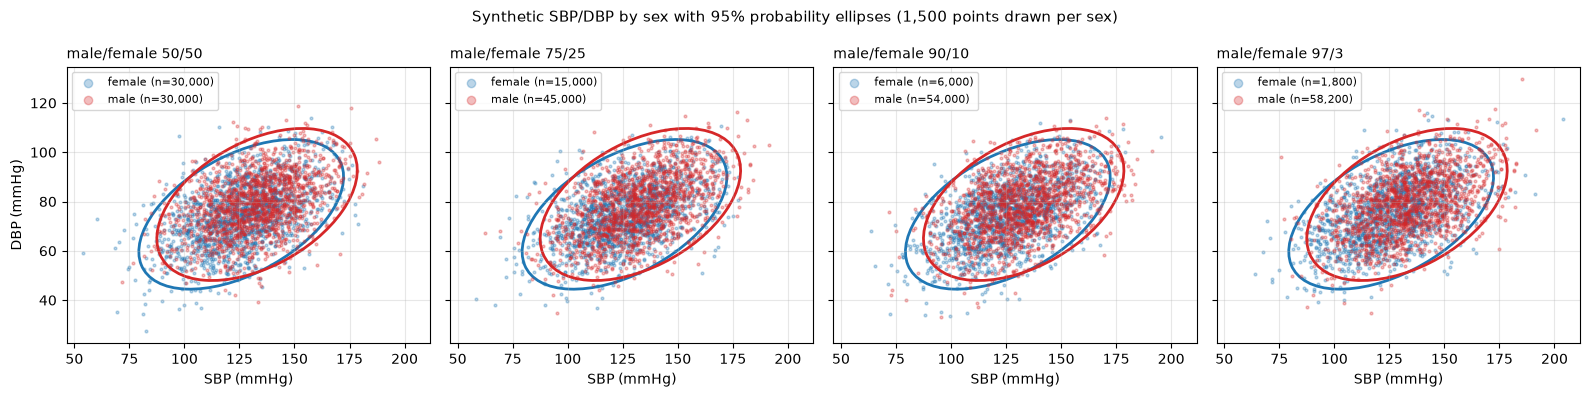

In [16]:
def ellipse_95(mean, cov, **kw):
    """Matplotlib Ellipse covering 95% of a bivariate normal with this mean and covariance."""
    vals, vecs = np.linalg.eigh(cov)                      # principal axes
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    scale = np.sqrt(5.991)                                # chi-square(2) 95% quantile
    return Ellipse(mean, 2 * scale * np.sqrt(vals[1]), 2 * scale * np.sqrt(vals[0]), angle=angle, **kw)


fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, d) in zip(axes, datasets.items()):
    for sex, label in [("female", 0), ("male", 1)]:
        sub = d[d.sex == label].sample(min(1500, (d.sex == label).sum()), random_state=0)
        ax.scatter(sub.sbp, sub.dbp, s=4, alpha=0.3, color=COLORS[sex],
                   label=f"{sex} (n={(d.sex==label).sum():,})")
        mean, cov = mean_cov(POP[sex])
        ax.add_patch(ellipse_95(mean, cov, fill=False, lw=2, color=COLORS[sex]))
    ax.set_title(f"male/female {name}", fontsize=10, loc="left")
    ax.set_xlabel("SBP (mmHg)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", markerscale=3)
axes[0].set_ylabel("DBP (mmHg)")
fig.suptitle("Synthetic SBP/DBP by sex with 95% probability ellipses (1,500 points drawn per sex)", fontsize=11)
fig.tight_layout()
fig.savefig("../figs/fig_synthetic_ellipses.png", dpi=150)

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score, recall_score

FEATURES = ["sbp", "dbp"]
balanced_test = make_dataset(10_000, 0.5, RNG)

def evaluate(clf, data):
    """AUC, accuracy, F1 and per-sex recall of a fitted classifier on one dataset."""
    X, y = data[FEATURES].values, data["sex"].values
    prob = clf.predict_proba(X)[:, 1] 
    pred = (prob >= 0.5).astype(int)
    return dict(
        AUC=roc_auc_score(y, prob),
        accuracy=accuracy_score(y, pred),
        F1=f1_score(y, pred),
        recall_male=recall_score(y, pred, pos_label=1),
        recall_female=recall_score(y, pred, pos_label=0),
        pred_male_frac=pred.mean(),
    )

splits, models, results = {}, {}, []
for name, d in datasets.items():
    train, test = train_test_split(d, test_size=0.30, stratify=d["sex"], random_state=0)
    splits[name] = (train, test)
    clf = LogisticRegression().fit(train[FEATURES].values, train["sex"].values)
    models[name] = clf
    for test_name, test_data in [("own test", test), ("balanced test", balanced_test)]:
        results.append(dict(ratio=name, test=test_name, **evaluate(clf, test_data)))

results = pd.DataFrame(results).set_index(["ratio", "test"])
results.to_csv("classifier_results.csv")
print(results.round(3).to_string())

                       AUC  accuracy     F1  recall_male  recall_female  pred_male_frac
ratio test                                                                             
50/50 own test       0.611     0.579  0.577        0.575          0.583           0.496
      balanced test  0.614     0.579  0.578        0.577          0.580           0.499
75/25 own test       0.619     0.750  0.857        0.998          0.008           0.996
      balanced test  0.615     0.503  0.668        0.999          0.007           0.996
90/10 own test       0.619     0.900  0.947        1.000          0.000           1.000
      balanced test  0.614     0.500  0.667        1.000          0.000           1.000
97/3  own test       0.617     0.970  0.985        1.000          0.000           1.000
      balanced test  0.613     0.500  0.667        1.000          0.000           1.000


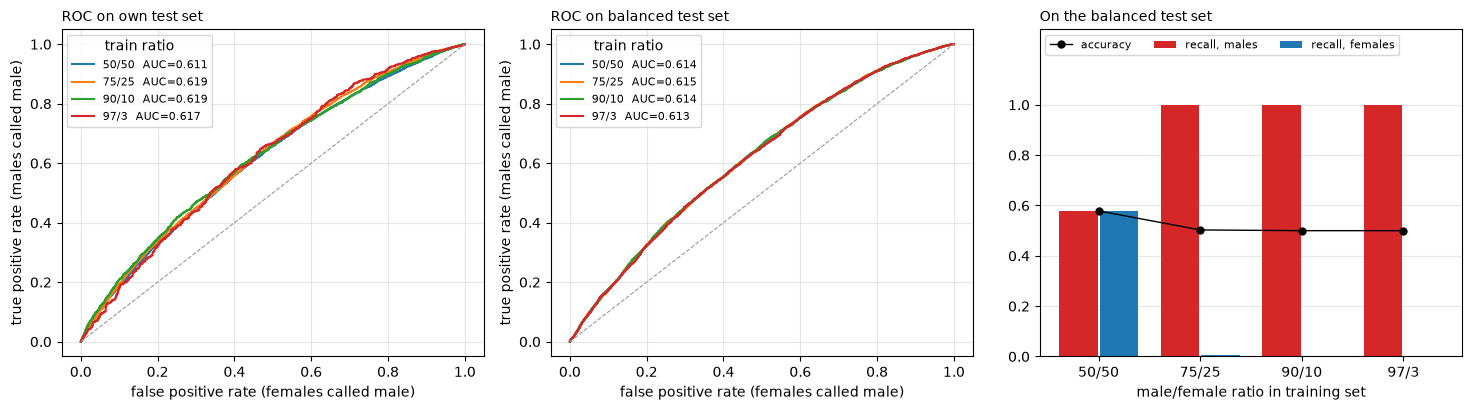

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, test_name in zip(axes[:2], ["own test", "balanced test"]):
    for name in RATIOS:
        data = splits[name][1] if test_name == "own test" else balanced_test
        prob = models[name].predict_proba(data[FEATURES].values)[:, 1]
        fpr, tpr, _ = roc_curve(data["sex"], prob)
        auc = results.loc[(name, test_name), "AUC"]
        ax.plot(fpr, tpr, lw=1.5, label=f"{name}  AUC={auc:.3f}")
    ax.plot([0, 1], [0, 1], color="0.6", lw=0.8, ls="--")
    ax.set_xlabel("false positive rate (females called male)")
    ax.set_ylabel("true positive rate (males called male)")
    ax.set_title(f"ROC on {test_name} set", fontsize=10, loc="left")
    ax.legend(fontsize=8, title="train ratio")
    ax.grid(alpha=0.3)

ax = axes[2]
bal = results.xs("balanced test", level="test")
x = np.arange(len(RATIOS))
ax.bar(x - 0.2, bal["recall_male"], 0.38, color=COLORS["male"], label="recall, males")
ax.bar(x + 0.2, bal["recall_female"], 0.38, color=COLORS["female"], label="recall, females")
ax.plot(x, bal["accuracy"], "ko-", ms=5, lw=1, label="accuracy")
ax.set_xticks(x, list(RATIOS))
ax.set_xlabel("male/female ratio in training set")
ax.set_ylim(0, 1.3)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title("On the balanced test set", fontsize=10, loc="left")
ax.legend(fontsize=8, loc="upper left", ncol=3)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("../figsfig_classifier.png", dpi=150)